# 03 — Exploratory Data Analysis
**Objective 2:** Understand structure, distributions, relationships, and textual patterns before modelling.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
REPORTS_DIR = PROJECT_ROOT / "outputs" / "reports"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

SENTIMENT_LABELS = ["negative", "neutral", "positive"]

def load_cleaned():
    for name in ("cleaned_reviews.parquet", "cleaned_reviews.pkl"):
        p = DATA_DIR / name
        if p.exists() and p.stat().st_size > 0:
            return pd.read_parquet(p) if name.endswith(".parquet") else pd.read_pickle(p)
    raise FileNotFoundError("Run 02_data_cleaning first")

df = load_cleaned()
print(df.shape)
df.head(2)


(35000, 28)


,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,bk_guest_id,bk_hotel_id,...,gt_country,gt_previous_stays,ht_hotel_name,ht_location,ht_star_rating,ht_total_rooms,review_text_clean,review_text_ml,text_length,word_count
0,1,1,6699,18,The overall price was fair for what we paid. M...,3.2,2025-06-02,neutral,6699,18,...,France,4,The Aberdeen Grand,Aberdeen,4,118,The overall price was fair for what we paid. M...,the overall price was fair for what we paid mi...,80,15
1,2,2,11380,23,The room was nothing out of the ordinary for w...,4.0,2025-01-22,positive,11380,23,...,Germany,4,Nottingham Park Hotel,Nottingham,4,95,The room was nothing out of the ordinary for w...,the room was nothing out of the ordinary for w...,158,28


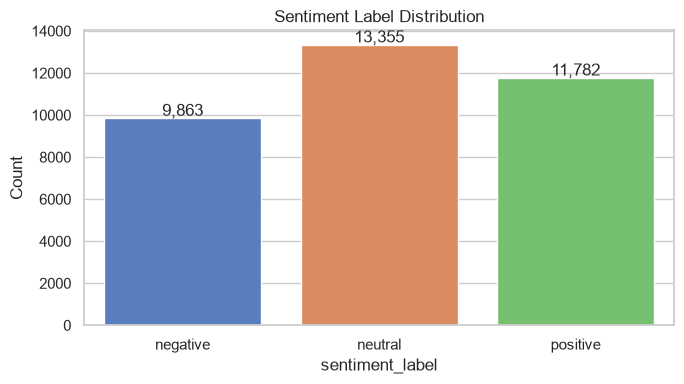

sentiment_label
negative     9863
neutral     13355
positive    11782
Name: count, dtype: int64


In [2]:
# Sentiment distribution
fig, ax = plt.subplots(figsize=(7, 4))
counts = df["sentiment_label"].value_counts().reindex(SENTIMENT_LABELS)
sns.barplot(x=counts.index, y=counts.values, ax=ax, hue=counts.index, legend=False)
ax.set_title("Sentiment Label Distribution")
ax.set_ylabel("Count")
for i, v in enumerate(counts.values):
    ax.text(i, v + 100, f"{v:,}", ha="center")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_sentiment_distribution.png", dpi=150)
plt.show()
print(counts)


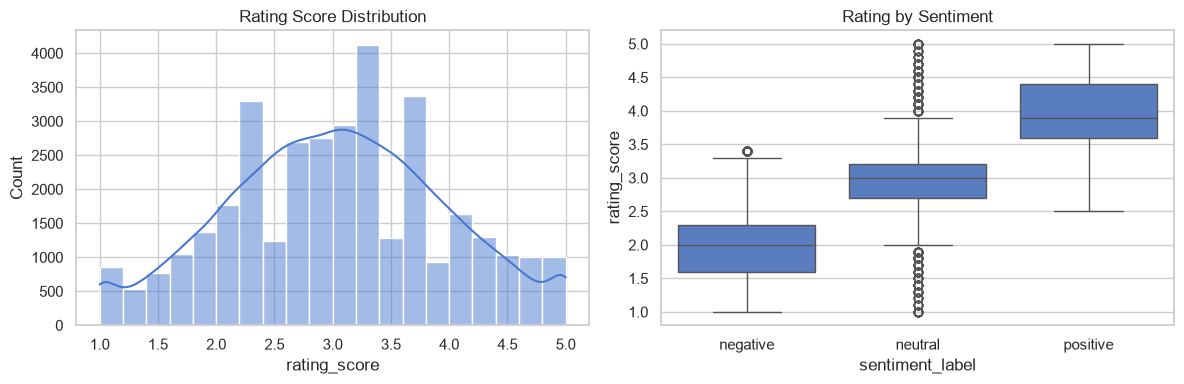

Mean rating: 3.03


In [3]:
# Rating distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["rating_score"], bins=20, kde=True, ax=axes[0])
axes[0].set_title("Rating Score Distribution")
sns.boxplot(x="sentiment_label", y="rating_score", data=df, order=SENTIMENT_LABELS, ax=axes[1])
axes[1].set_title("Rating by Sentiment")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_rating_distribution.png", dpi=150)
plt.show()
print("Mean rating:", round(df["rating_score"].mean(), 2))


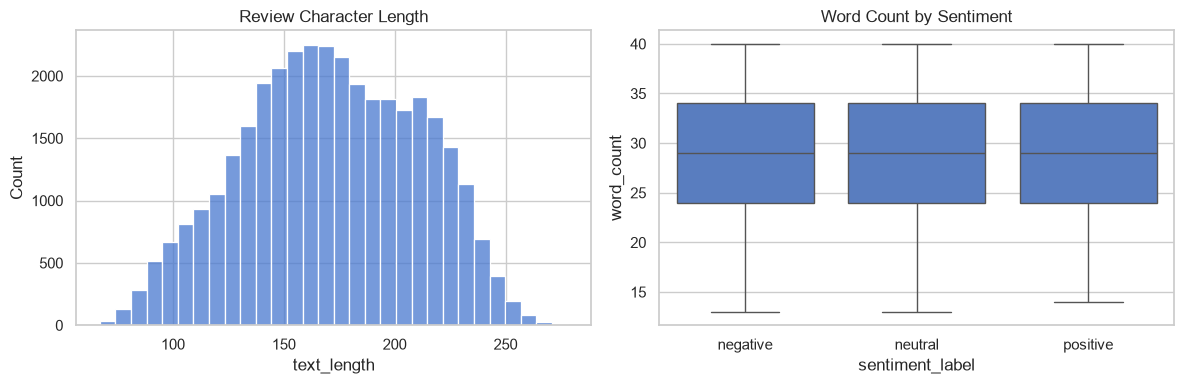

        text_length    word_count
count  35000.000000  35000.000000
mean     171.029943     28.865971
std       39.535144      6.527727
min       67.000000     13.000000
25%      143.000000     24.000000
50%      171.000000     29.000000
75%      202.000000     34.000000
max      278.000000     40.000000


In [4]:
# Text length
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["text_length"], bins=30, ax=axes[0])
axes[0].set_title("Review Character Length")
sns.boxplot(x="sentiment_label", y="word_count", data=df, order=SENTIMENT_LABELS, ax=axes[1])
axes[1].set_title("Word Count by Sentiment")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_text_length.png", dpi=150)
plt.show()
print(df[["text_length", "word_count"]].describe())


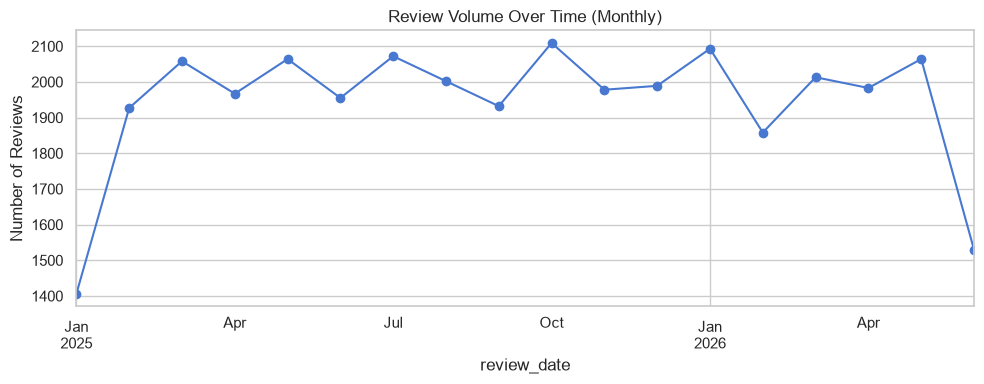

In [5]:
# Reviews over time
if "review_date" in df.columns:
    ts = df.set_index("review_date").resample("ME").size()
    fig, ax = plt.subplots(figsize=(10, 4))
    ts.plot(ax=ax, marker="o")
    ax.set_title("Review Volume Over Time (Monthly)")
    ax.set_ylabel("Number of Reviews")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "04_reviews_over_time.png", dpi=150)
    plt.show()


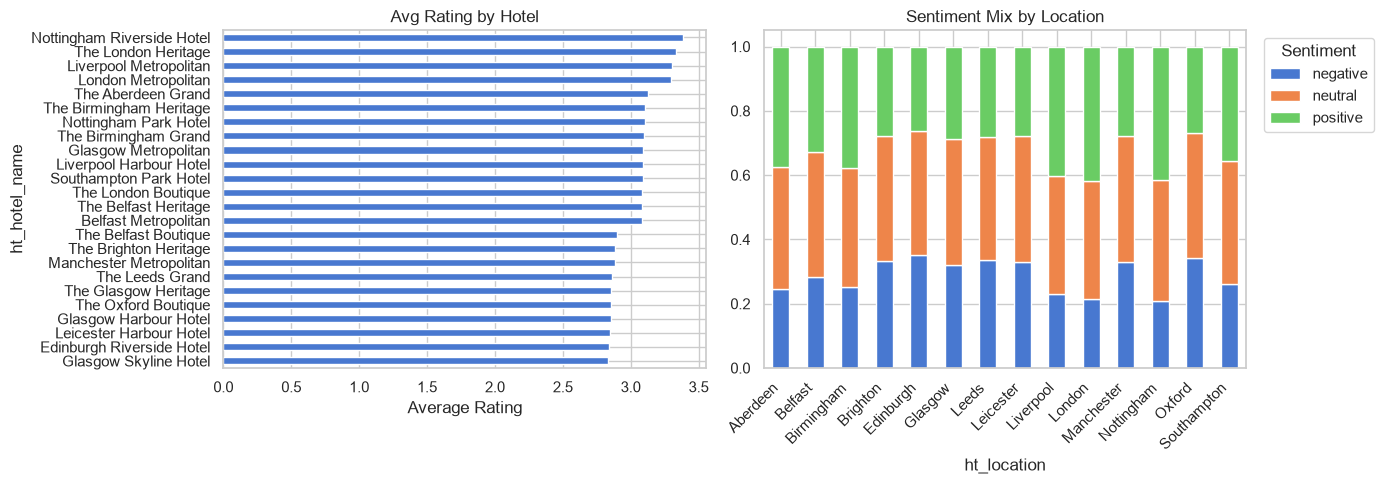

In [6]:
# Hotel patterns
hotel_col = "ht_hotel_name" if "ht_hotel_name" in df.columns else "hotel_id"
loc_col = "ht_location" if "ht_location" in df.columns else None

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
avg = df.groupby(hotel_col)["rating_score"].mean().sort_values()
avg.plot(kind="barh", ax=axes[0])
axes[0].set_title("Avg Rating by Hotel")
axes[0].set_xlabel("Average Rating")

if loc_col:
    ct = pd.crosstab(df[loc_col], df["sentiment_label"], normalize="index")
    ct[SENTIMENT_LABELS].plot(kind="bar", stacked=True, ax=axes[1])
    axes[1].set_title("Sentiment Mix by Location")
    axes[1].legend(title="Sentiment", bbox_to_anchor=(1.02, 1))
    plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_hotel_patterns.png", dpi=150)
plt.show()


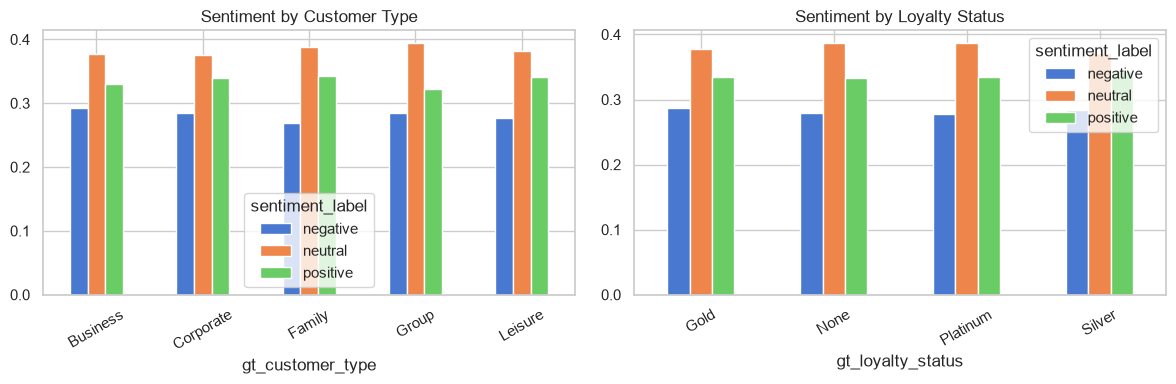

In [7]:
# Guest segments
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if "gt_customer_type" in df.columns:
    ct = pd.crosstab(df["gt_customer_type"], df["sentiment_label"], normalize="index")
    ct[SENTIMENT_LABELS].plot(kind="bar", ax=axes[0])
    axes[0].set_title("Sentiment by Customer Type")
    axes[0].tick_params(axis="x", rotation=30)
if "gt_loyalty_status" in df.columns:
    ct = pd.crosstab(df["gt_loyalty_status"], df["sentiment_label"], normalize="index")
    ct[SENTIMENT_LABELS].plot(kind="bar", ax=axes[1])
    axes[1].set_title("Sentiment by Loyalty Status")
    axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_guest_segments.png", dpi=150)
plt.show()


In [8]:
# Correlation summary
num_cols = [c for c in ["rating_score", "text_length", "word_count",
                         "bk_total_amount", "bk_stay_duration",
                         "ht_star_rating", "gt_previous_stays"] if c in df.columns]
corr = df[num_cols].corr().round(3)
display(corr)

# Summary stats for report
summary = {
    "n_reviews": len(df),
    "n_hotels": df["hotel_id"].nunique() if "hotel_id" in df.columns else "N/A",
    "n_guests": df["guest_id"].nunique() if "guest_id" in df.columns else "N/A",
    "mean_rating": round(df["rating_score"].mean(), 2),
    "mean_word_count": round(df["word_count"].mean(), 1),
    "sentiment_counts": df["sentiment_label"].value_counts().to_dict(),
}
print("\nEDA Summary:")
for k, v in summary.items():
    print(f"  {k}: {v}")


,rating_score,text_length,word_count,bk_total_amount,bk_stay_duration,ht_star_rating,gt_previous_stays
rating_score,1.000,0.069,0.003,0.003,0.008,0.182,0.007
text_length,0.069,1.000,0.946,-0.012,-0.008,0.026,-0.006
word_count,0.003,0.946,1.000,-0.013,-0.009,0.012,-0.005
bk_total_amount,0.003,-0.012,-0.013,1.000,0.753,-0.004,0.010
bk_stay_duration,0.008,-0.008,-0.009,0.753,1.000,0.002,0.010
ht_star_rating,0.182,0.026,0.012,-0.004,0.002,1.000,-0.010
gt_previous_stays,0.007,-0.006,-0.005,0.010,0.010,-0.010,1.000



EDA Summary:
  n_reviews: 35000
  n_hotels: 25
  n_guests: 11377
  mean_rating: 3.03
  mean_word_count: 28.9
  sentiment_counts: {'neutral': 13355, 'positive': 11782, 'negative': 9863}
